## 2. Feature Engineering

Input: per-station daily ride counts, MinMax scaled to [0, 1]. Single channel — no calendar features.

## 1. Setup & Data Prep

In [125]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import clear_output
from dotenv import load_dotenv
from sklearn.preprocessing import MinMaxScaler
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from divvy_demand.infra.s3_client import S3Client

load_dotenv('../../.env')
s3 = S3Client(env='prod')

station = s3.read_processed('station')
station['date'] = pd.to_datetime(station['date'])
print('Station table:', station.shape)
station.head()

Station table: (1404660, 7)


,date,start_station_name,start_station_id,total_rides,ebike_rides,member_rides,casual_rides
0,2020-01-01,63rd St Beach,101,2,0,2,0
1,2020-01-01,900 W Harrison St,109,1,0,1,0
2,2020-01-01,Aberdeen St & Jackson Blvd,21,2,0,2,0
3,2020-01-01,Aberdeen St & Monroe St,80,7,0,7,0
4,2020-01-01,Aberdeen St & Randolph St,621,3,0,3,0


In [126]:
YEARS_TRAIN = [2020, 2021, 2023]
YEARS_VAL   = [2024]

def load_year_pivots(years, station_df):
    raw = []
    for yr in years:
        df_yr = station_df[station_df['date'].dt.year == yr].copy()
        p = (
            df_yr.groupby(['start_station_name', 'date'])['total_rides']
            .sum().unstack('date').fillna(0)
        )
        raw.append(p)
    return raw

raw_train = load_year_pivots(YEARS_TRAIN, station)
raw_val   = load_year_pivots(YEARS_VAL,   station)

n_days = min(p.shape[1] for p in raw_train + raw_val)
print(f'Aligning all years to {n_days} days')

def align_and_concat(years, raw_list, n_days):
    pivots = []
    for yr, p in zip(years, raw_list):
        p = p.iloc[:, :n_days]
        p.columns = range(n_days)
        p.index = [f'{s}  [{yr}]' for s in p.index]
        pivots.append(p)
    return pd.concat(pivots, axis=0)

pivot_train_full = align_and_concat(YEARS_TRAIN, raw_train, n_days)
pivot_val_full   = align_and_concat(YEARS_VAL,   raw_val,   n_days)

print(f'Train: {pivot_train_full.shape[0]} station-years, {n_days} days  |  NaN: {pivot_train_full.isna().sum().sum()}')
print(f'Val:   {pivot_val_full.shape[0]}  station-years, {n_days} days  |  NaN: {pivot_val_full.isna().sum().sum()}')

Aligning all years to 364 days
Train: 3133 station-years, 364 days  |  NaN: 0
Val:   1809  station-years, 364 days  |  NaN: 0


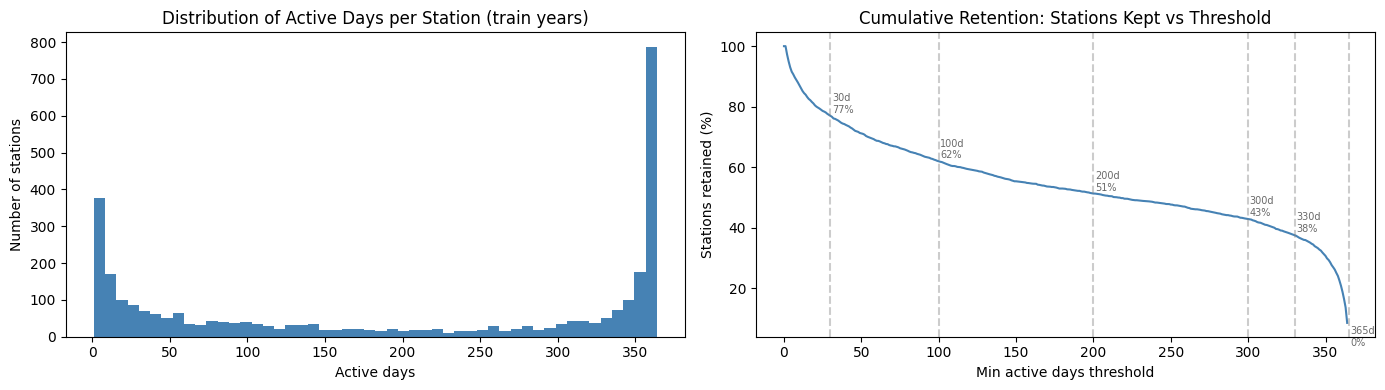


Decile breakdown:
  P  0: 1 active days
  P 10: 6 active days
  P 20: 21 active days
  P 30: 54 active days
  P 40: 114 active days
  P 50: 216 active days
  P 60: 317 active days
  P 70: 350 active days
  P 80: 360 active days
  P 90: 363 active days
  P100: 364 active days


In [127]:
# Active days distribution + cumulative retention curve
active_days_all = (pivot_train_full > 0).sum(axis=1).sort_values()
n_total = len(active_days_all)

thresholds = np.arange(0, pivot_train_full.shape[1] + 1, 1)
pct_kept = [(active_days_all >= t).sum() / n_total * 100 for t in thresholds]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(active_days_all.values, bins=50, color='steelblue', edgecolor='none')
axes[0].set_xlabel('Active days')
axes[0].set_ylabel('Number of stations')
axes[0].set_title('Distribution of Active Days per Station (train years)')

axes[1].plot(thresholds, pct_kept, color='steelblue')
axes[1].set_xlabel('Min active days threshold')
axes[1].set_ylabel('Stations retained (%)')
axes[1].set_title('Cumulative Retention: Stations Kept vs Threshold')

for t in [30, 100, 200, 300, 330, 365]:
    pct = (active_days_all >= t).sum() / n_total * 100
    axes[1].axvline(t, color='gray', linestyle='--', alpha=0.4)
    axes[1].text(t + 1, pct + 1, f'{t}d\n{pct:.0f}%', fontsize=7, color='dimgray')

plt.tight_layout()
plt.show()

print('\nDecile breakdown:')
for d in range(0, 11):
    q = np.percentile(active_days_all, d * 10)
    print(f'  P{d*10:3d}: {q:.0f} active days')

In [128]:
MIN_ACTIVE_DAYS = 7

pivot_train = pivot_train_full[(pivot_train_full > 0).sum(axis=1) >= MIN_ACTIVE_DAYS]
pivot_val   = pivot_val_full   # keep all 2024 stations for val
pivot       = pivot_train      # alias so downstream cells work unchanged
dates       = pivot.columns

print(f'Train (>= {MIN_ACTIVE_DAYS} active days): {len(pivot_train)} / {len(pivot_train_full)}')
print(f'Val (2024, no filter):                    {len(pivot_val)}')

Train (>= 7 active days): 2810 / 3133
Val (2024, no filter):                    1809


## 2. Feature Engineering

In [129]:
# Scale each station independently to [0, 1] — train and val scaled separately
rides_train = MinMaxScaler().fit_transform(pivot_train.T).T
rides_val   = MinMaxScaler().fit_transform(pivot_val.T).T

X_train = rides_train[:, None, :].astype('float32')  # (n_train, 1, n_days)
X_val   = rides_val[:, None, :].astype('float32')    # (n_val,   1, n_days)
X       = X_train   # alias for downstream cells

n_stations = len(pivot_train)
n_days     = pivot_train.shape[1]
dates      = pivot_train.columns

print(f'X_train: {X_train.shape}  range [{X_train.min():.3f}, {X_train.max():.3f}]')
print(f'X_val:   {X_val.shape}   range [{X_val.min():.3f}, {X_val.max():.3f}]')

X_train: (2810, 1, 364)  range [0.000, 1.000]
X_val:   (1809, 1, 364)   range [0.000, 1.000]


In [130]:
import re

# Load station coordinates
raw_frames = []
for month in [3, 6, 9]:
    raw = s3.read_raw(2023, month)
    raw_frames.append(raw[['start_station_name', 'start_lat', 'start_lng']].dropna())
coords_raw = pd.concat(raw_frames, ignore_index=True)
station_coords = (
    coords_raw.groupby('start_station_name')[['start_lat', 'start_lng']]
    .mean()
    .reset_index()
)

# Align to training stations only
base_names = [re.sub(r'\s+\[\d{4}\]$', '', n) for n in pivot_train.index]
coords_df = pd.DataFrame({'start_station_name': base_names}).merge(
    station_coords, on='start_station_name', how='left'
)

lat_min, lat_max = station_coords['start_lat'].min(), station_coords['start_lat'].max()
lng_min, lng_max = station_coords['start_lng'].min(), station_coords['start_lng'].max()

lat_norm = (coords_df['start_lat'].fillna(station_coords['start_lat'].mean()) - lat_min) / (lat_max - lat_min)
lng_norm = (coords_df['start_lng'].fillna(station_coords['start_lng'].mean()) - lng_min) / (lng_max - lng_min)

coords_array = np.stack([lat_norm.values, lng_norm.values], axis=1).astype(np.float32)

missing = coords_df['start_lat'].isna().sum()
print(f'Coords: {len(coords_df)} train stations, {missing} missing (filled with mean)')

Coords: 2810 train stations, 91 missing (filled with mean)


In [131]:
from sklearn.neighbors import NearestNeighbors

# ── Geographic k-NN weight matrix ─────────────────────────────────────────────
# coords_array is already normalized [0,1] lat/lon, shape (n_stations, 2)
K_GEO    = 10    # neighbors per station
SIGMA_GEO = 0.05  # Gaussian bandwidth in normalized coord space

nbrs = NearestNeighbors(n_neighbors=K_GEO + 1, metric='euclidean').fit(coords_array)
geo_dist, geo_idx = nbrs.kneighbors(coords_array)  # includes self at col 0

W = np.zeros((n_stations, n_stations), dtype=np.float32)
for i in range(n_stations):
    for j, d in zip(geo_idx[i], geo_dist[i]):
        if i != j:
            W[i, j] = np.exp(-(d ** 2) / (2 * SIGMA_GEO ** 2))

W = np.maximum(W, W.T)          # symmetrize
W_tensor = torch.tensor(W)      # kept on CPU; moved per-batch during training

print(f'W shape: {W.shape}')
print(f'Non-zero entries: {(W > 0).sum():,}  ({(W > 0).mean()*100:.1f}% density)')
print(f'Mean non-zero weight: {W[W > 0].mean():.4f}')

W shape: (2810, 2810)
Non-zero entries: 34,248  (0.4% density)
Mean non-zero weight: 0.9333


In [132]:
# Year-based split: 2020/2021/2023 → train, 2024 → val
X_tensor = torch.tensor(X_train, dtype=torch.float32)  # alias for downstream cells
X_val_t  = torch.tensor(X_val,   dtype=torch.float32)

# All training stations get an index for geo penalty lookup
train_sidx = torch.arange(n_stations, dtype=torch.long)

train_loader = DataLoader(TensorDataset(X_tensor, train_sidx), batch_size=64, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val_t),              batch_size=64, shuffle=False)

print(f'Train: {len(X_tensor)} station-years ({YEARS_TRAIN})')
print(f'Val:   {len(X_val_t)} station-years  ({YEARS_VAL})')

Train: 2810 station-years ([2020, 2021, 2023])
Val:   1809 station-years  ([2024])


## 3. Model Architecture

In [133]:
import math
import torch.nn.functional as F

N_FEATURES      = X.shape[1]  # 1
SEQ_LEN         = X.shape[2]  # 364
LATENT_CHANNELS = 2


class InceptionBlock1D(nn.Module):
    KERNELS = [2, 3, 4, 5, 6, 7, 14, 21, 30, 60, 91]

    def __init__(self, in_channels, out_per_branch):
        super().__init__()
        self.branches = nn.ModuleList([
            nn.Sequential(
                nn.Conv1d(in_channels, out_per_branch, kernel_size=k, padding=k // 2),
                nn.BatchNorm1d(out_per_branch),
                nn.ReLU(),
            )
            for k in self.KERNELS
        ])
        out_channels = out_per_branch * len(self.KERNELS)
        self.residual_proj = nn.Conv1d(in_channels, out_channels, kernel_size=1)

    def forward(self, x):
        outs = [b(x) for b in self.branches]
        min_len = min(o.shape[-1] for o in outs)
        out = torch.cat([o[..., :min_len] for o in outs], dim=1)
        res = self.residual_proj(x)[..., :min_len]
        return out + res


class CNNAutoencoder(nn.Module):
    def __init__(self, n_features, seq_len, latent_channels=3):
        super().__init__()
        self.seq_len = seq_len
        enc1_out = 8 * len(InceptionBlock1D.KERNELS)  # 88

        # Encoder
        self.enc1     = InceptionBlock1D(n_features, 8)               # (  1, T) -> (88, T)
        self.enc2     = nn.Sequential(
            nn.Conv1d(enc1_out, 64, kernel_size=7, padding=3),
            nn.BatchNorm1d(64), nn.ReLU(),
        )                                                              # (88, T) -> (64, T)
        self.enc3     = nn.Sequential(
            nn.Conv1d(64, 32, kernel_size=7, padding=3),
            nn.BatchNorm1d(32), nn.ReLU(),
        )                                                              # (64, T) -> (32, T)
        self.enc4     = nn.Sequential(
            nn.Conv1d(32, 16, kernel_size=7, padding=3),
            nn.BatchNorm1d(16), nn.ReLU(),
        )                                                              # (32, T) -> (16, T)
        self.enc_proj = nn.Conv1d(16, latent_channels, kernel_size=1) # (16, T) -> ( C, T)
        self.pool     = nn.Conv1d(latent_channels, latent_channels, kernel_size=7, stride=4,
                                  padding=3, groups=latent_channels)  # (C, T) -> (C, T/4)

        # Decoder
        self.dec_proj = nn.Conv1d(latent_channels, 16, kernel_size=1) # (C, T/4) -> (16, T/4)
        self.dec1     = nn.Sequential(
            nn.Conv1d(16, 32, kernel_size=7, padding=3), nn.ReLU(),
        )                                                              # (16, T/4) -> (32, T/4)
        self.dec2     = nn.Sequential(
            nn.Conv1d(32, 64, kernel_size=7, padding=3), nn.ReLU(),
        )                                                              # (32, T/4) -> (64, T/4)
        self.decoder_conv = nn.Sequential(
            nn.Upsample(size=seq_len),                                 # (64, T/4) -> (64, T)
            nn.Conv1d(64, enc1_out, kernel_size=7, padding=3), nn.ReLU(),
            nn.Conv1d(enc1_out, n_features, kernel_size=3, padding=1), nn.Sigmoid(),
        )                                                              # -> (1, T)

    def encode(self, x):
        return self.pool(self.enc_proj(self.enc4(self.enc3(self.enc2(self.enc1(x))))))

    def decode(self, z):
        return self.decoder_conv(self.dec2(self.dec1(self.dec_proj(z))))

    def forward(self, x):
        return self.decode(self.encode(x))


model = CNNAutoencoder(N_FEATURES, SEQ_LEN, LATENT_CHANNELS)
with torch.no_grad():
    dummy = torch.zeros(2, N_FEATURES, SEQ_LEN)
    z   = model.encode(dummy)
    out = model.decode(z)
    print(f'Input:   {tuple(dummy.shape)}')
    print(f'Latent:  {tuple(z.shape)}  -- {z.shape[1]} channels x {z.shape[2]} steps')
    print(f'Output:  {tuple(out.shape)}  {"ok" if out.shape == dummy.shape else "mismatch"}')
    print(f'Params:  {sum(p.numel() for p in model.parameters()):,}')

Input:   (2, 1, 364)
Latent:  (2, 2, 91)  -- 2 channels x 91 steps
Output:  (2, 1, 364)  ok
Params:  117,955


## 4. Training (live loss plot)

In [134]:
print(f'X NaN: {np.isnan(X).sum()}')
print(f'X Inf: {np.isinf(X).sum()}')
print(f'X range: [{X.min():.4f}, {X.max():.4f}]')

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
model_tmp = CNNAutoencoder(N_FEATURES, SEQ_LEN, LATENT_CHANNELS).to(device)
with torch.no_grad():
    test_batch = X_tensor[:8].to(device)
    out = model_tmp(test_batch)
    print(f'Forward pass NaN: {torch.isnan(out).sum().item()}')
    print(f'Forward pass range: [{out.min():.4f}, {out.max():.4f}]')

X NaN: 0
X Inf: 0
X range: [0.0000, 1.0000]
Forward pass NaN: 0
Forward pass range: [0.5175, 0.5243]


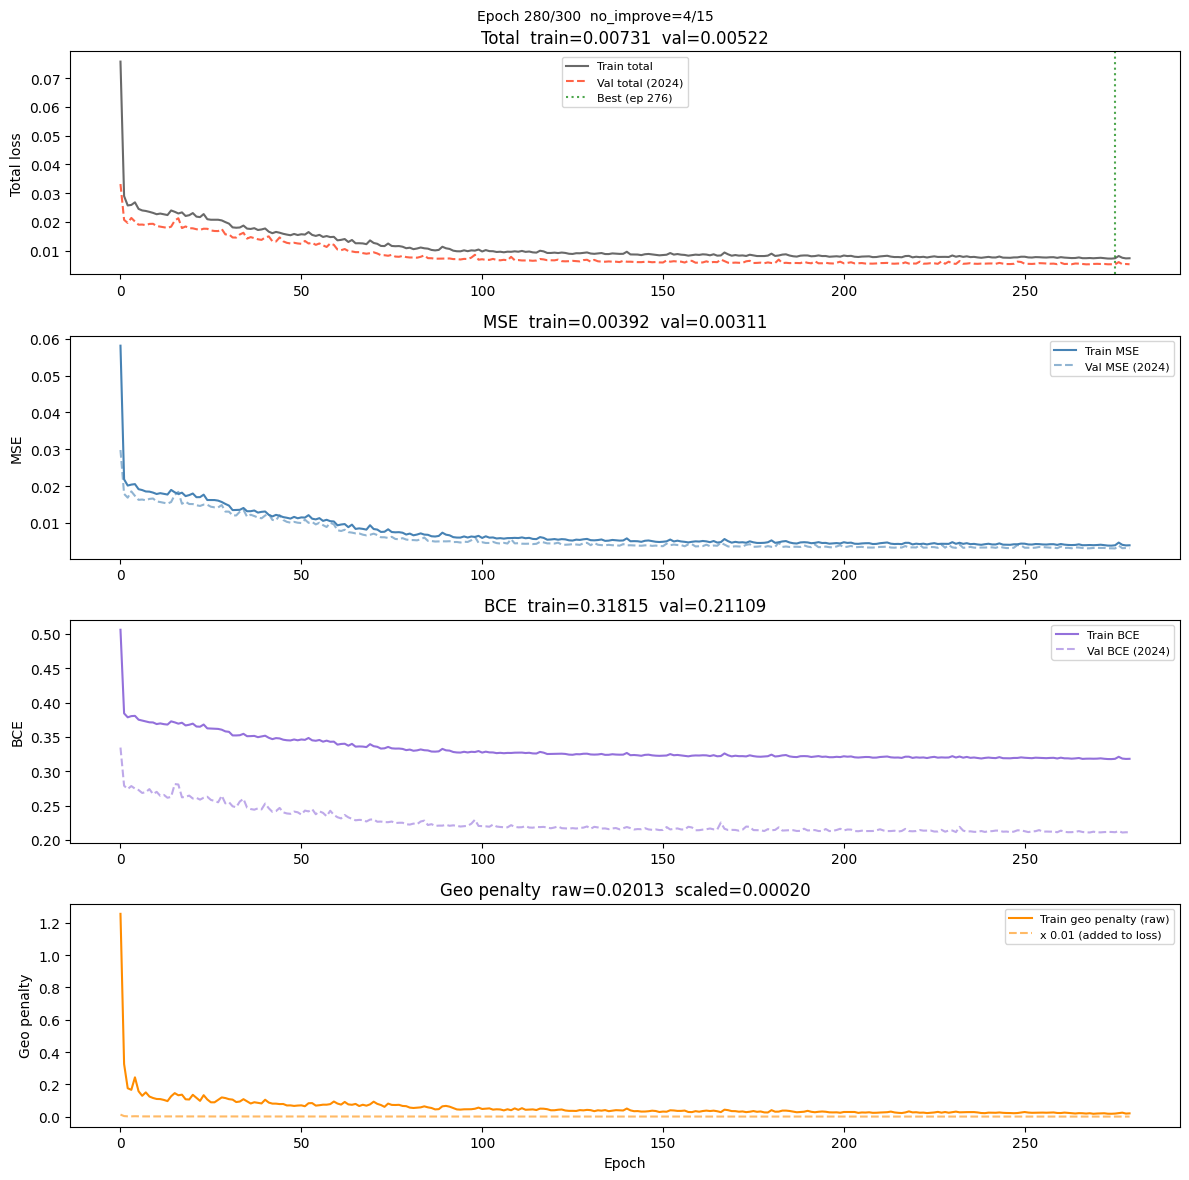

KeyboardInterrupt: 

In [135]:
EPOCHS     = 300
LR         = 1e-3
PATIENCE   = 15
MIN_DELTA  = 1e-6
LAMBDA_BCE = 0.01
LAMBDA_GEO = 0.01

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Device: {device}")

model     = CNNAutoencoder(N_FEATURES, SEQ_LEN, LATENT_CHANNELS).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
W_dev     = W_tensor.to(device)

def geo_penalty(z, sidx):
    z_flat  = z.reshape(len(z), -1)
    diff    = z_flat.unsqueeze(1) - z_flat.unsqueeze(0)
    d_lat   = (diff ** 2).sum(-1)
    w_batch = W_dev[sidx][:, sidx]
    w_sum   = w_batch.sum().clamp(min=1e-8)
    return (w_batch * d_lat).sum() / w_sum

train_mse_losses, train_bce_losses, train_geo_losses = [], [], []
val_mse_losses, val_bce_losses, val_losses = [], [], []
best_val   = float("inf")
best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
no_improve = 0

for epoch in range(1, EPOCHS + 1):
    # --- train ---
    model.train()
    t_mse = t_bce = t_geo = 0.0
    for batch, sidx in train_loader:
        batch, sidx = batch.to(device), sidx.to(device)
        z      = model.encode(batch)
        pred   = model.decode(z)
        m_loss = F.mse_loss(pred, batch)
        b_loss = F.binary_cross_entropy(pred, batch)
        g_loss = geo_penalty(z, sidx)
        loss   = m_loss + LAMBDA_BCE * b_loss + LAMBDA_GEO * g_loss
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        t_mse += m_loss.item() * len(batch)
        t_bce += b_loss.item() * len(batch)
        t_geo += g_loss.item() * len(batch)
    train_mse_losses.append(t_mse / n_stations)
    train_bce_losses.append(t_bce / n_stations)
    train_geo_losses.append(t_geo / n_stations)

    # --- val ---
    model.eval()
    v_mse = v_bce = 0.0
    with torch.no_grad():
        for (batch,) in val_loader:
            batch  = batch.to(device)
            pred   = model(batch)
            v_mse += F.mse_loss(pred, batch).item() * len(batch)
            v_bce += F.binary_cross_entropy(pred, batch).item() * len(batch)
    n_val = len(X_val_t)
    val_mse_losses.append(v_mse / n_val)
    val_bce_losses.append(v_bce / n_val)
    val_losses.append((v_mse + LAMBDA_BCE * v_bce) / n_val)

    # --- early stopping ---
    if val_losses[-1] < best_val - MIN_DELTA:
        best_val   = val_losses[-1]
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        no_improve = 0
    else:
        no_improve += 1

    # --- live plot every 5 epochs ---
    if epoch % 5 == 0 or epoch == 1 or no_improve == PATIENCE:
        clear_output(wait=True)
        fig, axes = plt.subplots(4, 1, figsize=(12, 12))

        total_train = [m + LAMBDA_BCE * b + LAMBDA_GEO * g
                       for m, b, g in zip(train_mse_losses, train_bce_losses, train_geo_losses)]
        axes[0].plot(total_train, label="Train total", color="dimgray")
        axes[0].plot(val_losses, label="Val total (2024)", linestyle="--", color="tomato")
        axes[0].axvline(len(val_losses) - no_improve - 1, color="green",
                        linestyle=":", alpha=0.7, label=f"Best (ep {len(val_losses)-no_improve})")
        axes[0].set_title(f"Total  train={total_train[-1]:.5f}  val={val_losses[-1]:.5f}")
        axes[0].set_ylabel("Total loss"); axes[0].legend(fontsize=8)

        axes[1].plot(train_mse_losses, label="Train MSE", color="steelblue")
        axes[1].plot(val_mse_losses, label="Val MSE (2024)", linestyle="--", color="steelblue", alpha=0.6)
        axes[1].set_title(f"MSE  train={train_mse_losses[-1]:.5f}  val={val_mse_losses[-1]:.5f}")
        axes[1].set_ylabel("MSE"); axes[1].legend(fontsize=8)

        axes[2].plot(train_bce_losses, color="mediumpurple", label="Train BCE")
        axes[2].plot(val_bce_losses, color="mediumpurple", linestyle="--", alpha=0.6, label="Val BCE (2024)")
        axes[2].set_title(f"BCE  train={train_bce_losses[-1]:.5f}  val={val_bce_losses[-1]:.5f}")
        axes[2].set_ylabel("BCE"); axes[2].legend(fontsize=8)

        axes[3].plot(train_geo_losses, color="darkorange", label="Train geo penalty (raw)")
        axes[3].plot([LAMBDA_GEO * g for g in train_geo_losses],
                     color="darkorange", linestyle="--", alpha=0.6,
                     label=f"x {LAMBDA_GEO} (added to loss)")
        axes[3].set_title(f"Geo penalty  raw={train_geo_losses[-1]:.5f}  scaled={LAMBDA_GEO*train_geo_losses[-1]:.5f}")
        axes[3].set_ylabel("Geo penalty"); axes[3].set_xlabel("Epoch")
        axes[3].legend(fontsize=8)

        fig.suptitle(f"Epoch {epoch}/{EPOCHS}  no_improve={no_improve}/{PATIENCE}", fontsize=10)
        plt.tight_layout()
        plt.show()

    if no_improve >= PATIENCE:
        print(f"Early stopping at epoch {epoch}")
        break

model.load_state_dict(best_state)
print(f"Restored best model (val={best_val:.6f})")

## 5. Reconstruction Check

In [ ]:
model.eval()
with torch.no_grad():
    X_recon    = model(X_tensor.to(device)).cpu().numpy()
    Z_temporal = model.encode(X_tensor.to(device)).cpu().numpy()  # (n_stations, C, T_latent)

Z = Z_temporal.reshape(len(Z_temporal), -1)  # flat for clustering

recon_error = np.mean((X[:, 0, :] - X_recon[:, 0, :]) ** 2, axis=1)
print(f'Mean ride-channel MSE: {recon_error.mean():.5f}')
print(f'\nWorst 5 stations:')
for i in np.argsort(recon_error)[-5:][::-1]:
    print(f'  {pivot.index[i]}: {recon_error[i]:.5f}')

Mean ride-channel MSE: 0.01824

Worst 5 stations:
  Clinton St & Washington Blvd  [2023]: 0.06991
  Damen Ave & 51st St  [2021]: 0.06933
  LaSalle St & Jackson Blvd  [2023]: 0.06138
  Canal St & Adams St  [2023]: 0.05980
  Halsted St & 56th St  [2020]: 0.05860


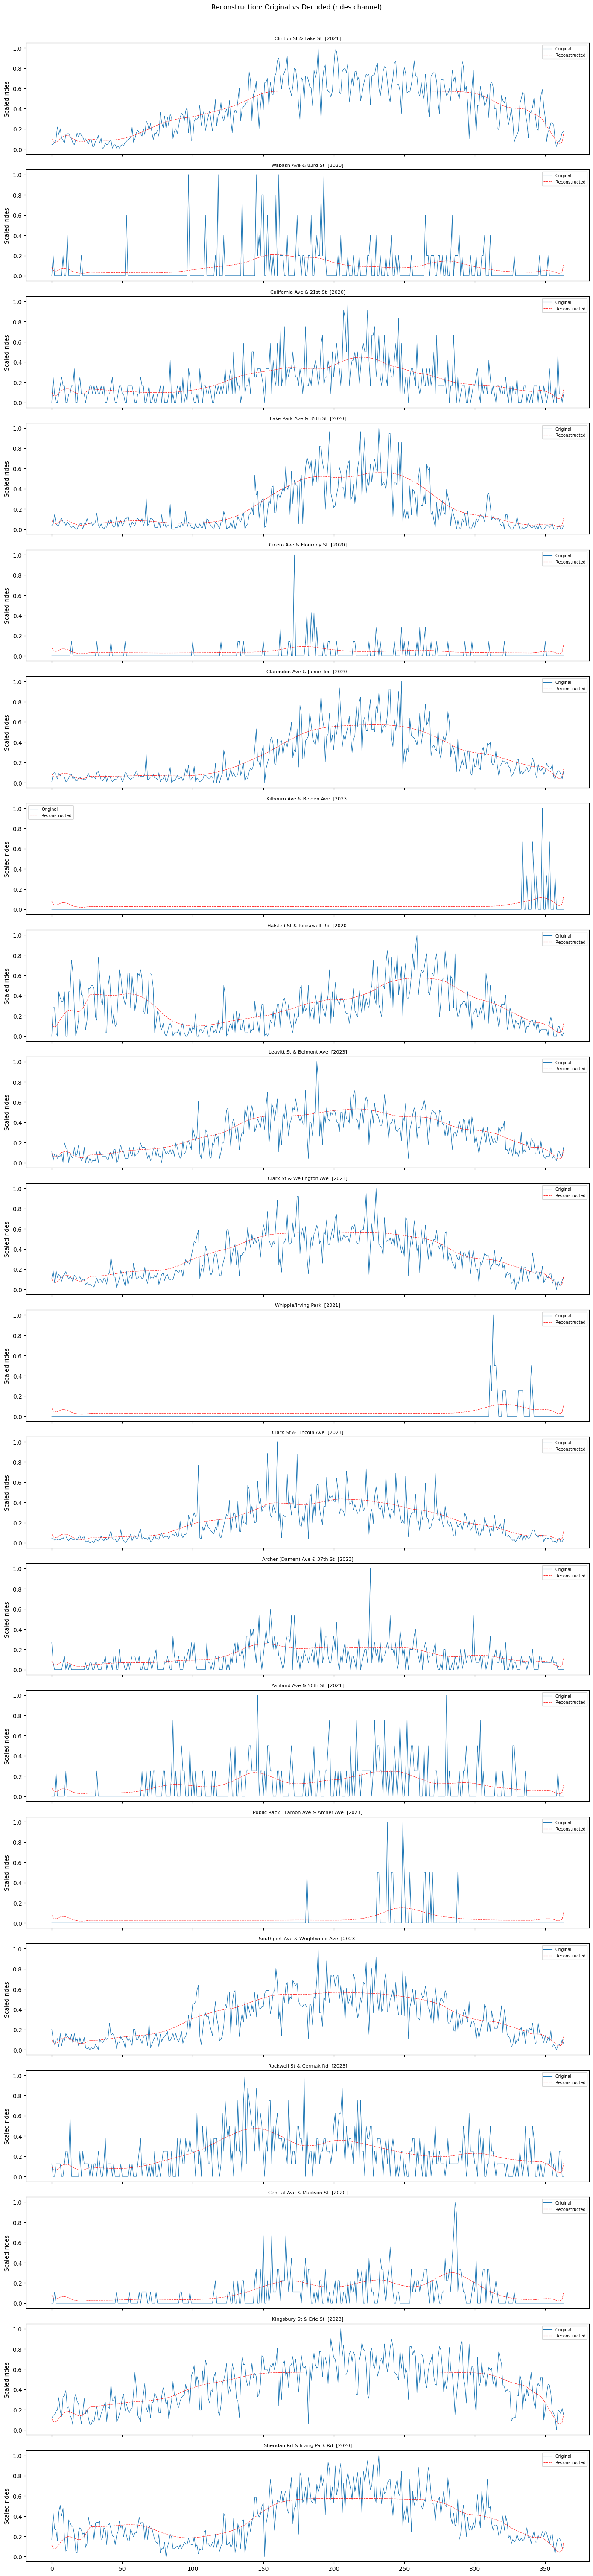

In [ ]:
# Plot original vs reconstruction — rides channel — 6 random stations
np.random.seed(0)
sample_idx = np.random.choice(n_stations, 20, replace=False)


fig, axes = plt.subplots(20, 1, figsize=(14, 60), sharex=True)
for ax, idx in zip(axes, sample_idx):
    ax.plot(dates, X[idx, 0, :], label='Original', linewidth=0.8)
    ax.plot(dates, X_recon[idx, 0, :], label='Reconstructed', linewidth=0.8,
            linestyle='--', color='red', alpha=0.8)
    ax.set_title(pivot.index[idx], fontsize=8)
    ax.set_ylabel('Scaled rides')
    ax.legend(fontsize=7)
fig.suptitle('Reconstruction: Original vs Decoded (rides channel)', fontsize=11, y=1.005)
plt.tight_layout()
plt.show()

## 6. Latent Space — K-means + t-SNE

In [ ]:
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from matplotlib.colors import ListedColormap

KM_PALETTE = ['#FF0000','#0070FF','#00CC00','#FF00FF','#FF8C00',
              '#00CED1','#8B008B','#2E8B57','#FF6347','#4169E1']

# ── t-SNE on flattened temporal latent (no lat/lon channels) ──────────────────
TSNE_PERP = 30
print('Running t-SNE...')
tsne_2d = TSNE(n_components=2, perplexity=TSNE_PERP, random_state=42).fit_transform(Z)
print('Done.')

# ── K-means elbow ─────────────────────────────────────────────────────────────
K_RANGE = range(2, 13)
inertias = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(Z)
    inertias.append(km.inertia_)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(list(K_RANGE), inertias, 'o-', color='steelblue')
ax.set_xlabel('K')
ax.set_ylabel('Inertia (WCSS)')
ax.set_title('K-means Elbow — pick K at the bend')
plt.tight_layout()
plt.show()

# ── Fit chosen K ──────────────────────────────────────────────────────────────
K_KM = 6   # adjust based on elbow
km = KMeans(n_clusters=K_KM, random_state=42, n_init=10)
km_labels = km.fit_predict(Z)
km_colors = [KM_PALETTE[k % len(KM_PALETTE)] for k in range(K_KM)]
print(f'K-means (K={K_KM}) cluster sizes: {dict(zip(*np.unique(km_labels, return_counts=True)))}')

# ── t-SNE coloured by cluster + mean traffic ──────────────────────────────────
mean_rides_all = pivot.values.mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (c, title, cm) in zip(axes, [
    (km_labels,      f'K-means clusters (K={K_KM})', ListedColormap(km_colors)),
    (mean_rides_all, 'Mean daily rides',              'viridis'),
]):
    sc = ax.scatter(tsne_2d[:, 0], tsne_2d[:, 1], c=c, cmap=cm,
                    s=8, alpha=0.75, linewidths=0)
    plt.colorbar(sc, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('t-SNE 1')
    ax.set_ylabel('t-SNE 2')
plt.suptitle(f't-SNE of latent space  (perplexity={TSNE_PERP})', fontsize=10)
plt.tight_layout()
plt.show()

# ── Top-3 stations per cluster by mean daily traffic ─────────────────────────
TOP_N = 3

fig, axes = plt.subplots(
    K_KM, TOP_N,
    figsize=(5 * TOP_N, 2.5 * K_KM),
    sharex=False, sharey=False,
)
for row, k in enumerate(range(K_KM)):
    mask_k    = np.where(km_labels == k)[0]
    top_local = mask_k[np.argsort(mean_rides_all[mask_k])[::-1][:TOP_N]]
    color     = km_colors[k]
    for col, stn_idx in enumerate(top_local):
        ax  = axes[row][col]
        raw = pivot.values[stn_idx]
        ax.plot(range(n_days), raw, color=color, linewidth=0.9)
        ax.fill_between(range(n_days), raw, alpha=0.18, color=color)
        ax.set_title(
            f'{pivot.index[stn_idx][:42]}\n'
            f'Cluster {k}  |  mean {mean_rides_all[stn_idx]:.1f} rides/day',
            fontsize=7, pad=3,
        )
        ax.tick_params(labelsize=6)

fig.suptitle(f'Top-{TOP_N} stations by mean daily traffic per K-means cluster', fontsize=10)
plt.tight_layout()
plt.show()

Running t-SNE...


KeyboardInterrupt: 

In [ ]:
import folium

# Strip year tag, keep first occurrence per base station name
base_names_all = [re.sub(r'\s+\[\d{4}\]$', '', n) for n in pivot.index]
km_cluster_df = pd.DataFrame({
    'start_station_name': base_names_all,
    'cluster': km_labels,
}).drop_duplicates('start_station_name')

map_df_km = km_cluster_df.merge(station_coords, on='start_station_name', how='left')
map_df_km = map_df_km.dropna(subset=['start_lat', 'start_lng'])
print(f'K-means stations on map: {len(map_df_km)}')

m_km = folium.Map(location=[41.8781, -87.6298], zoom_start=11, tiles='CartoDB positron')

for k in range(K_KM):
    fg = folium.FeatureGroup(name=f'Cluster {k}')
    subset = map_df_km[map_df_km['cluster'] == k]
    for _, row in subset.iterrows():
        folium.CircleMarker(
            location=[row['start_lat'], row['start_lng']],
            radius=4, color=km_colors[k],
            fill=True, fill_color=km_colors[k], fill_opacity=0.8, weight=1,
            tooltip=f"{row['start_station_name']}  (cluster {k})",
        ).add_to(fg)
    fg.add_to(m_km)

folium.LayerControl(collapsed=False).add_to(m_km)

legend_items = ''.join([
    f'<div><svg height="12" width="12"><circle cx="6" cy="6" r="5" fill="{km_colors[k]}"/></svg>'
    f'<span style="padding-left:6px;">Cluster {k} ({(map_df_km["cluster"]==k).sum()})</span></div>'
    for k in range(K_KM)
])
m_km.get_root().html.add_child(folium.Element(
    '<div style="position:fixed;bottom:50px;right:50px;width:160px;border:2px solid grey;'
    'z-index:9999;font-size:11px;background:white;padding:8px;border-radius:5px;">'
    f'<b>K-means (K={K_KM})</b><hr style="margin:6px 0">' + legend_items + '</div>'
))
m_km.save('km_cluster_map.html')
print('Saved to km_cluster_map.html')
m_km

K-means stations on map: 1270
Saved to km_cluster_map.html


: 

: 

: 

### Spectral Clustering on Latent Space

Eigengap suggests K = 1


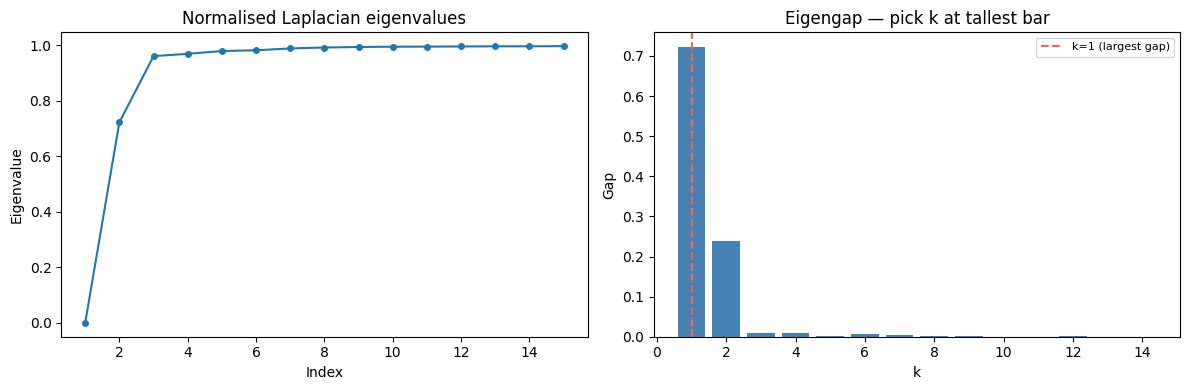

Spectral (K=6) cluster sizes: {np.int32(0): np.int64(273), np.int32(1): np.int64(942), np.int32(2): np.int64(304), np.int32(3): np.int64(387), np.int32(4): np.int64(766), np.int32(5): np.int64(138)}


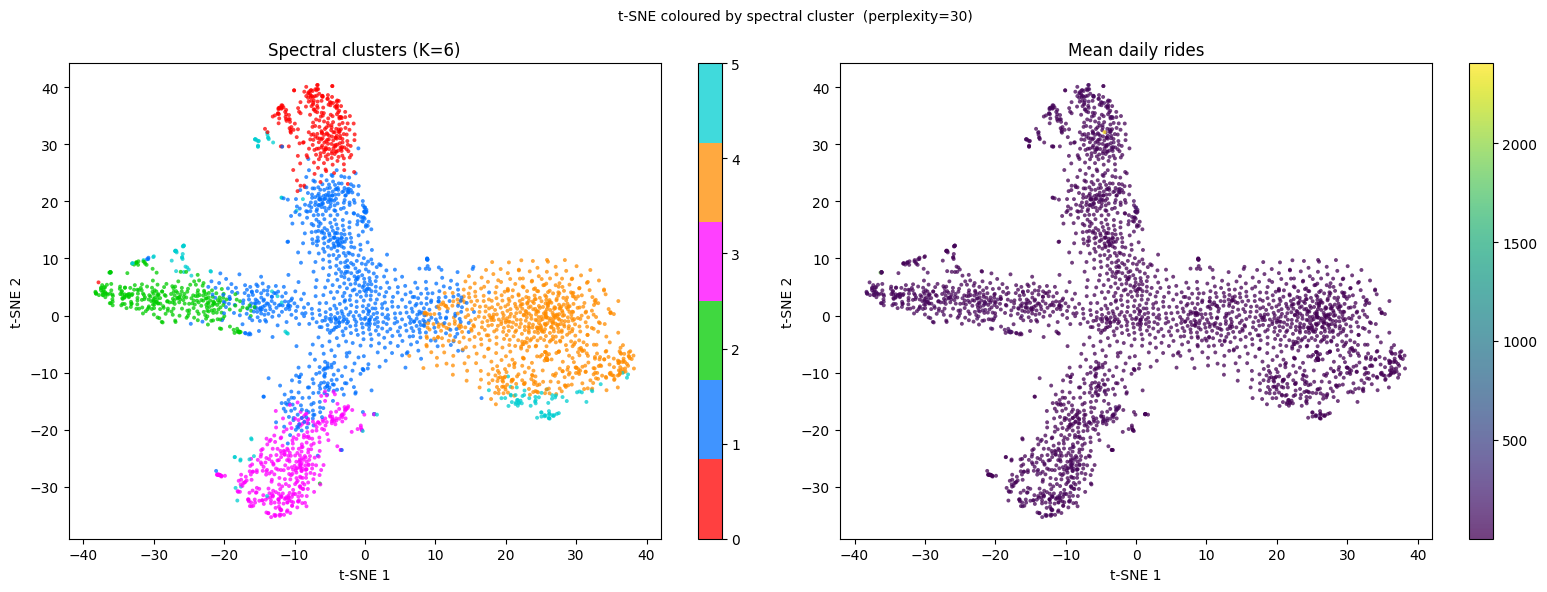

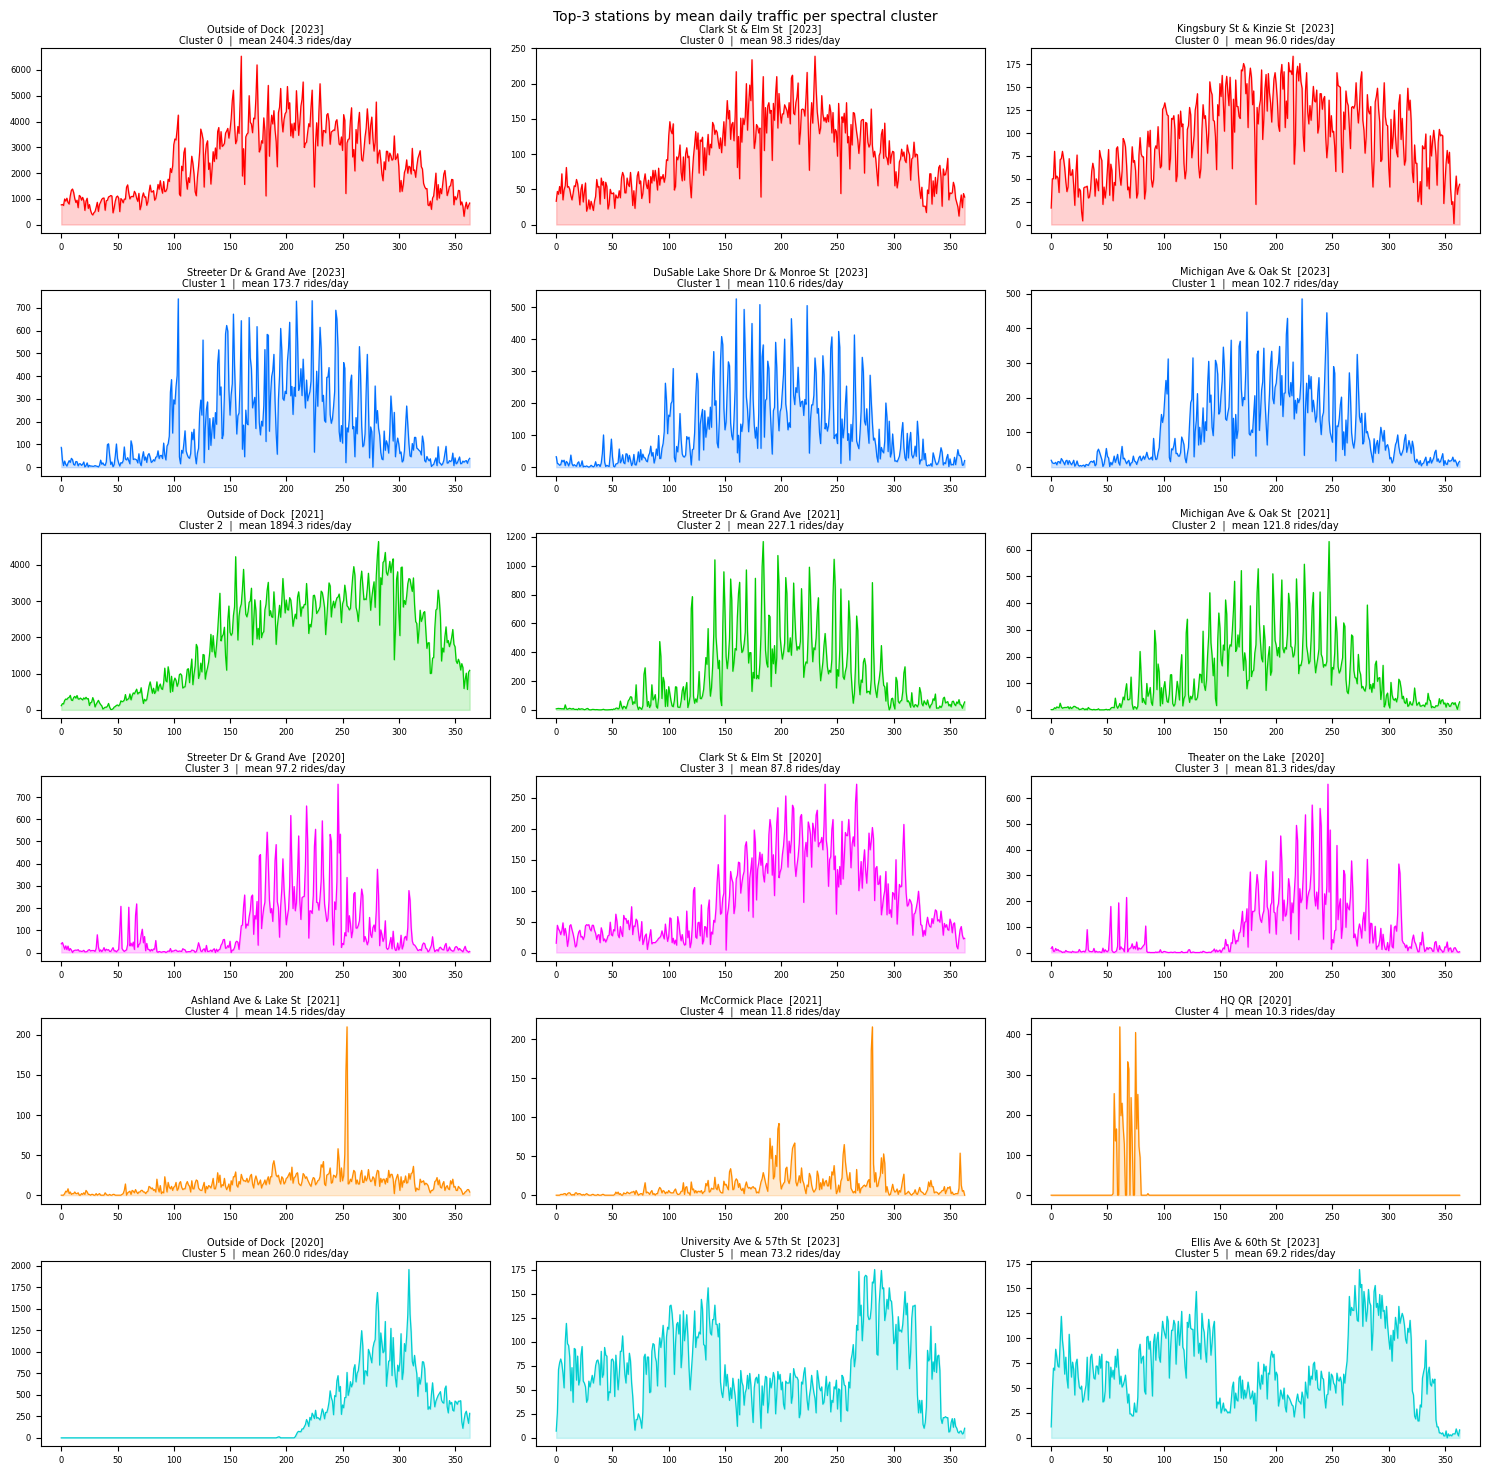

: 

: 

: 

In [ ]:
from sklearn.cluster import SpectralClustering
from sklearn.metrics.pairwise import rbf_kernel
from scipy.sparse.csgraph import laplacian
from scipy.sparse.linalg import eigsh
from scipy.sparse import csr_matrix

# ── Build RBF affinity from Euclidean latent distances ────────────────────────
# gamma = 1 / (2 * median_sq_dist) — data-adaptive bandwidth
sq_dists  = np.sum((Z[:, None, :] - Z[None, :, :]) ** 2, axis=-1)
gamma     = 1.0 / (2.0 * np.median(sq_dists[sq_dists > 0]))
affinity  = np.exp(-gamma * sq_dists)
np.fill_diagonal(affinity, 0)

# ── Eigengap heuristic ────────────────────────────────────────────────────────
K_MAX = 15
L = laplacian(csr_matrix(affinity), normed=True)
eigenvalues = eigsh(L, k=K_MAX, which='SM', return_eigenvectors=False)
eigenvalues = np.sort(np.abs(eigenvalues))
gaps   = np.diff(eigenvalues)
k_auto = int(np.argmax(gaps) + 1)
print(f'Eigengap suggests K = {k_auto}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(range(1, K_MAX + 1), eigenvalues, 'o-', markersize=4)
axes[0].set_xlabel('Index'); axes[0].set_ylabel('Eigenvalue')
axes[0].set_title('Normalised Laplacian eigenvalues')
axes[1].bar(range(1, K_MAX), gaps, color='steelblue')
axes[1].axvline(k_auto, color='tomato', linestyle='--', label=f'k={k_auto} (largest gap)')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Gap')
axes[1].set_title('Eigengap — pick k at tallest bar')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

# ── Fit spectral clustering ───────────────────────────────────────────────────
K_SP = 6   # override here if needed, e.g. K_SP = 7
np.fill_diagonal(affinity, 1)   # restore self-affinity for sklearn
sp_labels = SpectralClustering(
    n_clusters=K_SP, affinity='precomputed',
    random_state=42, n_jobs=-1,
).fit_predict(affinity)
sp_colors = [KM_PALETTE[k % len(KM_PALETTE)] for k in range(K_SP)]
print(f'Spectral (K={K_SP}) cluster sizes: {dict(zip(*np.unique(sp_labels, return_counts=True)))}')

# ── t-SNE: cluster vs mean traffic ───────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, (c, title, cm) in zip(axes, [
    (sp_labels,      f'Spectral clusters (K={K_SP})', ListedColormap(sp_colors)),
    (mean_rides_all, 'Mean daily rides',               'viridis'),
]):
    sc = ax.scatter(tsne_2d[:, 0], tsne_2d[:, 1], c=c, cmap=cm,
                    s=8, alpha=0.75, linewidths=0)
    plt.colorbar(sc, ax=ax)
    ax.set_title(title)
    ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2')
plt.suptitle(f't-SNE coloured by spectral cluster  (perplexity={TSNE_PERP})', fontsize=10)
plt.tight_layout()
plt.show()

# ── Top-3 stations per cluster by mean daily traffic ─────────────────────────
TOP_N = 3

fig, axes = plt.subplots(
    K_SP, TOP_N,
    figsize=(5 * TOP_N, 2.5 * K_SP),
    sharex=False, sharey=False,
)
for row, k in enumerate(range(K_SP)):
    mask_k    = np.where(sp_labels == k)[0]
    top_local = mask_k[np.argsort(mean_rides_all[mask_k])[::-1][:TOP_N]]
    color     = sp_colors[k]
    for col, stn_idx in enumerate(top_local):
        ax  = axes[row][col]
        raw = pivot.values[stn_idx]
        ax.plot(range(n_days), raw, color=color, linewidth=0.9)
        ax.fill_between(range(n_days), raw, alpha=0.18, color=color)
        ax.set_title(
            f'{pivot.index[stn_idx][:42]}\n'
            f'Cluster {k}  |  mean {mean_rides_all[stn_idx]:.1f} rides/day',
            fontsize=7, pad=3,
        )
        ax.tick_params(labelsize=6)

fig.suptitle(f'Top-{TOP_N} stations by mean daily traffic per spectral cluster', fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
sp_cluster_df = pd.DataFrame({
    'start_station_name': base_names_all,
    'cluster': sp_labels,
}).drop_duplicates('start_station_name')

map_df_sp = sp_cluster_df.merge(station_coords, on='start_station_name', how='left')
map_df_sp = map_df_sp.dropna(subset=['start_lat', 'start_lng'])
print(f'Spectral stations on map: {len(map_df_sp)}')

m_sp = folium.Map(location=[41.8781, -87.6298], zoom_start=11, tiles='CartoDB positron')

for k in range(K_SP):
    fg = folium.FeatureGroup(name=f'Cluster {k}')
    subset = map_df_sp[map_df_sp['cluster'] == k]
    for _, row in subset.iterrows():
        folium.CircleMarker(
            location=[row['start_lat'], row['start_lng']],
            radius=4, color=sp_colors[k],
            fill=True, fill_color=sp_colors[k], fill_opacity=0.8, weight=1,
            tooltip=f"{row['start_station_name']}  (cluster {k})",
        ).add_to(fg)
    fg.add_to(m_sp)

folium.LayerControl(collapsed=False).add_to(m_sp)

legend_items = ''.join([
    f'<div><svg height="12" width="12"><circle cx="6" cy="6" r="5" fill="{sp_colors[k]}"/></svg>'
    f'<span style="padding-left:6px;">Cluster {k} ({(map_df_sp["cluster"]==k).sum()})</span></div>'
    for k in range(K_SP)
])
m_sp.get_root().html.add_child(folium.Element(
    '<div style="position:fixed;bottom:50px;right:50px;width:160px;border:2px solid grey;'
    'z-index:9999;font-size:11px;background:white;padding:8px;border-radius:5px;">'
    f'<b>Spectral (K={K_SP})</b><hr style="margin:6px 0">' + legend_items + '</div>'
))
m_sp.save('spectral_cluster_map.html')
print('Saved to spectral_cluster_map.html')
m_sp

: 

: 

: 

## 6. Latent Space — Hierarchical Clustering + DTW

In [ ]:
# from dtaidistance import dtw
# from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
# from scipy.spatial.distance import squareform
# from sklearn.metrics import silhouette_score

# # Select stations active on >95% of days (lose at most 5%)
# min_active_days = int(0.95 * pivot.shape[1])
# active_mask = (pivot > 0).sum(axis=1) > min_active_days
# top100_names = pivot[active_mask].index
# top100_idx = [i for i, name in enumerate(pivot.index) if name in set(top100_names)]
# print(f"Stations active on >{min_active_days}/365 days selected for DTW: {len(top100_idx)}")

# # Extract latent series for top 100: (100, latent_len)
# Z_series = Z_temporal[top100_idx, 0, :].astype(np.double)
# print(f"DTW input shape: {Z_series.shape}")

# # Pure Python fallback (C library not compiled)
# dist_matrix = dtw.distance_matrix(Z_series, use_c=False, parallel=True)
# dist_matrix[~np.isfinite(dist_matrix)] = dist_matrix[np.isfinite(dist_matrix)].max()
# print("Distance matrix computed.")

# condensed = squareform(dist_matrix)
# linkage_matrix = linkage(condensed, method="complete")
# print("Linkage matrix computed.")


: 

: 

: 

In [ ]:
# # Dendrogram
# plt.figure(figsize=(14, 5))
# dendrogram(
#     linkage_matrix,
#     truncate_mode='lastp', p=30,
#     leaf_rotation=90, leaf_font_size=10,
#     show_contracted=True,
# )
# plt.axhline(y=np.median(linkage_matrix[:, 2]), color='red', linestyle='--', label='Median distance')
# plt.title('Hierarchical Clustering Dendrogram (truncated)')
# plt.xlabel('Station index')
# plt.ylabel('DTW distance')
# plt.legend()
# plt.tight_layout()
# plt.show()


: 

: 

: 

In [ ]:
# # Elbow (WCSS) + Silhouette to pick K
# K_range = range(2, 12)
# wcss, silhouettes = [], []

# for k in K_range:
#     labels = fcluster(linkage_matrix, k, criterion='maxclust')
#     # WCSS using DTW distances
#     wc = 0
#     for ci in range(1, k + 1):
#         idx = np.where(labels == ci)[0]
#         if len(idx) > 1:
#             sub = dist_matrix[np.ix_(idx, idx)]
#             wc += (sub ** 2).sum() / (2 * len(idx))
#     wcss.append(wc)
#     silhouettes.append(silhouette_score(dist_matrix, labels, metric='precomputed'))

# fig, axes = plt.subplots(1, 2, figsize=(14, 4))
# axes[0].plot(K_range, wcss, 'o-')
# axes[0].set_title('Elbow (WCSS)')
# axes[0].set_xlabel('K')
# axes[0].set_ylabel('WCSS')

# axes[1].plot(K_range, silhouettes, 'o-', color='orange')
# axes[1].set_title('Silhouette Score')
# axes[1].set_xlabel('K')
# axes[1].set_ylabel('Score')

# plt.tight_layout()
# plt.show()
# best_k = list(K_range)[silhouettes.index(max(silhouettes))]
# print(f'Best K by silhouette: {best_k}  ({max(silhouettes):.4f})')


: 

: 

: 

In [ ]:
# # Apply chosen K
# K = 6  # override here if needed

# clusters = fcluster(linkage_matrix, K, criterion="maxclust") - 1  # 0-indexed

# for k in range(K):
#     print(f"Cluster {k}: {(clusters == k).sum()} stations")

# # Real ride counts for top-100 stations: (100, 365)
# real_values = pivot.iloc[top100_idx].values  # raw daily rides

# dates = pd.to_datetime(pivot.columns)

# fig, axes = plt.subplots(K, 1, figsize=(14, K * 3), sharex=True)
# if K == 1: axes = [axes]
# for k, ax in enumerate(axes):
#     mask = clusters == k
#     mean_r = real_values[mask].mean(axis=0)
#     std_r  = real_values[mask].std(axis=0)
#     ax.plot(dates, mean_r, label=f"Cluster {k} (n={mask.sum()})")
#     ax.fill_between(dates, mean_r - std_r, mean_r + std_r, alpha=0.2)
#     ax.set_ylabel("Daily rides")
#     ax.legend()
# axes[-1].set_xlabel("Date")
# fig.suptitle("Mean Daily Ride Profile per Cluster (top-100 stations)", fontsize=11)
# plt.tight_layout()
# plt.show()


: 

: 

: 

In [ ]:
# ## t-SNE on DTW distance matrix
# from sklearn.manifold import TSNE

# TSNE_PERPLEXITY = 30   # playable: try 10, 30, 50

# # dist_matrix may have tiny negative values from float precision — clip
# dist_sym = np.maximum(dist_matrix, 0)

# embedding_2d = TSNE(
#     n_components=2,
#     metric='precomputed',
#     perplexity=TSNE_PERPLEXITY,
#     random_state=42,
#     init='random',   # 'pca' not available with precomputed metric
# ).fit_transform(dist_sym)

# mean_rides_top = pivot.iloc[top100_idx].mean(axis=1).values
# cmap = plt.get_cmap('tab10', K)

# fig, axes = plt.subplots(1, 2, figsize=(16, 6))
# for ax, (c, title, cm) in zip(axes, [
#     (clusters,       f'DTW hierarchical clusters  (K={K})', 'tab10'),
#     (mean_rides_top, 'Mean annual rides',                   'viridis'),
# ]):
#     sc = ax.scatter(embedding_2d[:, 0], embedding_2d[:, 1],
#                     c=c, cmap=cm, s=20, alpha=0.8, linewidths=0)
#     plt.colorbar(sc, ax=ax)
#     ax.set_title(title); ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2')

# plt.suptitle(f't-SNE of DTW distance matrix  (perplexity={TSNE_PERPLEXITY})', fontsize=10)
# plt.tight_layout(); plt.show()


: 

: 

: 

In [ ]:
# ## Spectral clustering on DTW distance matrix
# from sklearn.cluster import SpectralClustering
# from sklearn.neighbors import kneighbors_graph
# from scipy.sparse.csgraph import laplacian
# from scipy.sparse.linalg import eigsh
# from scipy.sparse import csr_matrix
# from matplotlib.colors import to_rgba

# # Shared palette — used by both time series plots and map
# SP_PALETTE = ['#FF0000','#0070FF','#00CC00','#FF00FF','#FF8C00',
#               '#00CED1','#8B008B','#2E8B57','#FF6347','#4169E1']

# # Convert DTW distances to affinity: RBF kernel
# sigma    = np.median(dist_sym[dist_sym > 0])
# affinity = np.exp(-(dist_sym ** 2) / (2 * sigma ** 2))
# np.fill_diagonal(affinity, 0)  # zero self-affinity for Laplacian

# # ── Eigengap heuristic ─────────────────────────────────────
# L = laplacian(csr_matrix(affinity), normed=True)
# K_MAX = 15
# eigenvalues = eigsh(L, k=K_MAX, which='SM', return_eigenvectors=False)
# eigenvalues = np.sort(np.abs(eigenvalues))
# gaps   = np.diff(eigenvalues)
# k_auto = int(np.argmax(gaps) + 1)
# print(f'Eigengap suggests k = {k_auto}')

# fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# axes[0].plot(range(1, K_MAX + 1), eigenvalues, marker='o', markersize=4)
# axes[0].set_xlabel('Index'); axes[0].set_ylabel('Eigenvalue')
# axes[0].set_title('Laplacian eigenvalues')
# axes[1].bar(range(1, K_MAX), gaps, color='steelblue')
# axes[1].axvline(k_auto, color='tomato', linestyle='--', label=f'k={k_auto} (largest gap)')
# axes[1].set_xlabel('k'); axes[1].set_ylabel('Eigenvalue gap')
# axes[1].set_title('Eigengap — pick k at tallest bar')
# axes[1].legend(fontsize=8)
# plt.tight_layout(); plt.show()

# # ── Fit spectral clustering ────────────────────────────────
# np.fill_diagonal(affinity, 1)  # restore self-affinity for sklearn
# K_SPECTRAL = 7            # change to a fixed int to override
# sp_labels = SpectralClustering(
#     n_clusters=K_SPECTRAL, affinity='precomputed',
#     random_state=42, n_jobs=-1,
# ).fit_predict(affinity)
# print(f'Cluster sizes: {dict(zip(*np.unique(sp_labels, return_counts=True)))}')

# # colours indexed by cluster id — same list the map will use
# sp_colors = [SP_PALETTE[k % len(SP_PALETTE)] for k in range(K_SPECTRAL)]

# # ── t-SNE coloured by cluster ──────────────────────────────
# from matplotlib.colors import ListedColormap
# cmap_sp = ListedColormap(sp_colors)
# fig, axes = plt.subplots(1, 2, figsize=(16, 6))
# for ax, (c, title, cm) in zip(axes, [
#     (sp_labels,      f'Spectral clusters  (k={K_SPECTRAL})', cmap_sp),
#     (mean_rides_top, 'Mean annual rides',                    'viridis'),
# ]):
#     sc = ax.scatter(embedding_2d[:, 0], embedding_2d[:, 1],
#                     c=c, cmap=cm, s=20, alpha=0.8, linewidths=0)
#     plt.colorbar(sc, ax=ax)
#     ax.set_title(title); ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2')
# plt.suptitle(f'Spectral clustering on DTW distance  (perplexity={TSNE_PERPLEXITY})', fontsize=10)
# plt.tight_layout(); plt.show()

# # ── Mean profile per cluster ───────────────────────────────
# fig, axes = plt.subplots(K_SPECTRAL, 1, figsize=(14, 2.5 * K_SPECTRAL), sharex=True)
# if K_SPECTRAL == 1: axes = [axes]
# for k, ax in enumerate(axes):
#     mask     = sp_labels == k
#     profiles = real_values[mask]
#     color    = sp_colors[k]
#     ax.plot(dates, profiles.T, color=color, alpha=0.15, linewidth=0.5)
#     ax.plot(dates, profiles.mean(axis=0), color=color, linewidth=1.8,
#             label=f'Cluster {k}  (n={mask.sum()})')
#     ax.set_ylabel('Daily rides'); ax.legend(fontsize=8, loc='upper left')
#     ax.tick_params(labelsize=6)
# axes[-1].set_xlabel('Date')
# fig.suptitle('Spectral — mean ride profile per cluster', fontsize=10)
# plt.tight_layout(); plt.show()


: 

: 

: 

In [ ]:
# ## Spectral clustering — Folium map
# import folium

# # station_coords already fetched above; SP_PALETTE and sp_colors from dtw_spectral
# cluster_df = pd.DataFrame({
#     'start_station_name': pivot.index[top100_idx],
#     'cluster': sp_labels,
# })
# map_df = cluster_df.merge(station_coords, on='start_station_name', how='left')
# map_df = map_df.dropna(subset=['start_lat', 'start_lng'])
# print(f'Stations on map: {len(map_df)}')

# cluster_ids = sorted(map_df['cluster'].unique())
# color_map   = {k: sp_colors[k] for k in cluster_ids}  # same as profile plots

# m = folium.Map(location=[41.8781, -87.6298], zoom_start=11, tiles='OpenStreetMap')

# station_groups = {k: folium.FeatureGroup(name=f'Cluster {k} stations') for k in cluster_ids}
# for _, row in map_df.iterrows():
#     k = row['cluster']
#     folium.CircleMarker(
#         location=[row['start_lat'], row['start_lng']],
#         radius=4, color=color_map[k],
#         fill=True, fill_color=color_map[k], fill_opacity=0.75, weight=1,
#         popup=folium.Popup(f"<b>{row['start_station_name']}</b><br>Cluster {k}", max_width=250),
#         tooltip=row['start_station_name'],
#     ).add_to(station_groups[k])
# for g in station_groups.values():
#     g.add_to(m)

# density_groups = {k: folium.FeatureGroup(name=f'Cluster {k} density', show=False) for k in cluster_ids}
# for _, row in map_df.iterrows():
#     k = row['cluster']
#     folium.CircleMarker(
#         location=[row['start_lat'], row['start_lng']],
#         radius=15, color=color_map[k],
#         fill=True, fill_color=color_map[k], fill_opacity=0.12, weight=1, opacity=0.3,
#     ).add_to(density_groups[k])
# for g in density_groups.values():
#     g.add_to(m)

# folium.LayerControl(collapsed=True).add_to(m)

# legend_items = ''.join([
#     f'<div><svg height="12" width="12"><circle cx="6" cy="6" r="5" fill="{color_map[k]}"/></svg>'
#     f'<span style="padding-left:8px;">Cluster {k} ({(map_df["cluster"]==k).sum()} stations)</span></div><br>'
#     for k in cluster_ids
# ])
# legend_html = (
#     '<div style="position:fixed;bottom:50px;right:50px;width:200px;'
#     'border:2px solid grey;z-index:9999;font-size:10px;'
#     'background-color:white;padding:8px;border-radius:5px;'
#     'box-shadow:0 0 15px rgba(0,0,0,0.2);">'
#     '<div style="text-align:center;"><b>Divvy Spectral Clusters (DTW)</b></div>'
#     '<hr style="margin:8px 0;">'
#     + legend_items +
#     '</div>'
# )
# m.get_root().html.add_child(folium.Element(legend_html))

# m.save('cluster_map_spectral.html')
# print('Saved to cluster_map_spectral.html')
# m


: 

: 

: 

In [ ]:
# ## Spectral clustering — top 3 stations by ride count per cluster
# TOP_N = 3   # playable

# mean_rides_stn = pivot.iloc[top100_idx].mean(axis=1).values  # mean daily rides per station
# cluster_ids    = sorted(np.unique(sp_labels))

# fig, axes = plt.subplots(
#     len(cluster_ids), TOP_N,
#     figsize=(5 * TOP_N, 2.5 * len(cluster_ids)),
#     sharex=True, sharey=False,
# )
# if len(cluster_ids) == 1:
#     axes = [axes]

# for row, k in enumerate(cluster_ids):
#     local_mask   = np.where(sp_labels == k)[0]
#     sorted_local = local_mask[np.argsort(mean_rides_stn[local_mask])[::-1][:TOP_N]]
#     global_idx   = [top100_idx[j] for j in sorted_local]  # back into full pivot
#     color        = sp_colors[k]

#     for col, stn_idx in enumerate(global_idx):
#         ax  = axes[row][col]
#         raw = pivot.iloc[stn_idx].values
#         ax.plot(dates, raw, color=color, linewidth=0.9)
#         ax.fill_between(dates, raw, alpha=0.18, color=color)
#         ax.set_title(
#             f'{pivot.index[stn_idx][:35]}\n'
#             f'Cluster {k}  |  mean {pivot.iloc[stn_idx].mean():.0f} rides/day',
#             fontsize=7, pad=3,
#         )
#         ax.tick_params(labelsize=6)
#         ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter('%b'))

# fig.suptitle(f'Top-{TOP_N} stations by mean daily rides per cluster (spectral)', fontsize=10)
# plt.tight_layout(); plt.show()


: 

: 

: 

## 7. Cluster Map (Folium)

In [ ]:
# # Extract station lat/lon from a few months of raw trip data
# # Average coordinates per station name (same approach as original project)
# raw_frames = []
# for month in [3, 6, 9]:  # Mar/Jun/Sep gives good coverage
#     raw = s3.read_raw(2023, month)
#     raw_frames.append(raw[['start_station_name', 'start_lat', 'start_lng']].dropna())

# coords_df = pd.concat(raw_frames, ignore_index=True)
# station_coords = (
#     coords_df.groupby('start_station_name')[['start_lat', 'start_lng']]
#     .mean()
#     .reset_index()
# )
# print(f'Stations with coords: {len(station_coords)}')

: 

: 

: 

In [ ]:
# import folium

# # Build cluster assignment dataframe (top-100 stations used for DTW)
# cluster_df = pd.DataFrame({
#     'start_station_name': pivot.index[top100_idx],
#     'cluster': clusters,
# })
# map_df = cluster_df.merge(station_coords, on='start_station_name', how='left')
# map_df = map_df.dropna(subset=['start_lat', 'start_lng'])
# print(f'Stations on map: {len(map_df)}')

# # Distinct hex colors — one per cluster
# PALETTE = ['#FF0000','#0070FF','#00CC00','#FF00FF','#FF8C00',
#            '#00CED1','#8B008B','#2E8B57','#FF6347','#4169E1']
# cluster_ids = sorted(map_df['cluster'].unique())
# color_map = {k: PALETTE[i % len(PALETTE)] for i, k in enumerate(cluster_ids)}

# chicago_coords = [41.8781, -87.6298]
# m = folium.Map(location=chicago_coords, zoom_start=11, tiles='OpenStreetMap')

# # Station markers — small circles, one toggleable feature group per cluster
# station_groups = {k: folium.FeatureGroup(name=f'Cluster {k} stations') for k in cluster_ids}
# for _, row in map_df.iterrows():
#     k = row['cluster']
#     folium.CircleMarker(
#         location=[row['start_lat'], row['start_lng']],
#         radius=4,
#         color=color_map[k],
#         fill=True, fill_color=color_map[k], fill_opacity=0.75, weight=1,
#         popup=folium.Popup(f"<b>{row['start_station_name']}</b><br>Cluster {k}", max_width=250),
#         tooltip=row['start_station_name'],
#     ).add_to(station_groups[k])
# for g in station_groups.values():
#     g.add_to(m)

# # Density overlay — large semi-transparent circles, hidden by default
# density_groups = {k: folium.FeatureGroup(name=f'Cluster {k} density', show=False) for k in cluster_ids}
# for _, row in map_df.iterrows():
#     k = row['cluster']
#     folium.CircleMarker(
#         location=[row['start_lat'], row['start_lng']],
#         radius=15,
#         color=color_map[k],
#         fill=True, fill_color=color_map[k], fill_opacity=0.12, weight=1, opacity=0.3,
#     ).add_to(density_groups[k])
# for g in density_groups.values():
#     g.add_to(m)

# folium.LayerControl(collapsed=True).add_to(m)

# # Legend
# legend_items = ''.join([
#     f'<div><svg height="12" width="12"><circle cx="6" cy="6" r="5" fill="{color_map[k]}"/></svg>'
#     f'<span style="padding-left:8px;">Cluster {k} ({(map_df["cluster"]==k).sum()} stations)</span></div><br>'
#     for k in cluster_ids
# ])
# legend_html = (
#     '<div style="position:fixed;bottom:50px;right:50px;width:160px;'
#     'border:2px solid grey;z-index:9999;font-size:10px;'
#     'background-color:white;padding:8px;border-radius:5px;'
#     'box-shadow:0 0 15px rgba(0,0,0,0.2);">'
#     '<div style="text-align:center;"><b>Divvy Station Clusters</b></div>'
#     '<hr style="margin:8px 0;">'
#     + legend_items +
#     '</div>'
# )
# m.get_root().html.add_child(folium.Element(legend_html))

# m.save("cluster_map.html")
# print("Saved to cluster_map.html — open in browser for tiles")
# m


: 

: 

: 

In [ ]:
# # Reconstruction for stations containing "University"
# uni_mask = pd.Series(pivot.index).str.contains('University', case=False).values
# uni_idx = np.where(uni_mask)[0]

# print(f'University stations found: {len(uni_idx)}')
# for i in uni_idx:
#     print(f'  [{i}] {pivot.index[i]}')

: 

: 

: 

In [ ]:
# fig, axes = plt.subplots(len(uni_idx), 1, figsize=(14, 4 * len(uni_idx)), sharex=True)
# if len(uni_idx) == 1:
#     axes = [axes]

# for ax, idx in zip(axes, uni_idx):
#     orig  = X[idx, 0, :]
#     recon = X_recon[idx, 0, :]
#     mse   = np.mean((orig - recon) ** 2)
#     cluster_id = clusters[idx]

#     ax.plot(dates, orig,  linewidth=0.9, label='Original')
#     ax.plot(dates, recon, linewidth=0.9, linestyle='--', color='red', alpha=0.85, label='Reconstructed')
#     ax.fill_between(dates, orig, recon, alpha=0.15, color='red')
#     ax.set_title(f'{pivot.index[idx]}  |  Cluster {cluster_id}  |  MSE={mse:.5f}', fontsize=9)
#     ax.set_ylabel('Scaled rides')
#     ax.legend(fontsize=8)

# axes[-1].set_xlabel('Date')
# fig.suptitle('University Stations — Reconstruction', fontsize=11, y=1.005)
# plt.tight_layout()
# plt.show()

: 

: 

: 

In [ ]:
# # Sample 5 stations and visualize original series + latent temporal representation
# np.random.seed(7)
# sample_idx = np.random.choice(len(pivot), 5, replace=False)

# # latent time axis — 46 compressed steps mapped back to approximate dates
# T_latent   = Z_temporal.shape[2]  # 46
# latent_dates = pd.date_range(dates[0], dates[-1], periods=T_latent)

# fig, axes = plt.subplots(5, 2, figsize=(16, 18),
#                           gridspec_kw={'width_ratios': [3, 1]})

# for row, idx in enumerate(sample_idx):
#     station_name = pivot.index[idx]
#     cluster_id   = clusters[idx]

#     # --- Left: original 365-day series ---
#     ax_orig = axes[row, 0]
#     ax_orig.plot(dates, X[idx, 0, :], linewidth=0.9, color='steelblue')
#     ax_orig.fill_between(dates, X[idx, 0, :], alpha=0.2, color='steelblue')
#     ax_orig.set_title(f'{station_name}  |  Cluster {cluster_id}', fontsize=9)
#     ax_orig.set_ylabel('Scaled rides')
#     ax_orig.set_xlabel('Date')

#     # --- Right: latent temporal channels as heatmap (latent_channels x T_latent) ---
#     ax_lat = axes[row, 1]
#     z = Z_temporal[idx]  # (latent_channels, T_latent)
#     im = ax_lat.imshow(z, aspect='auto', cmap='RdBu_r',
#                        vmin=-np.abs(z).max(), vmax=np.abs(z).max(),
#                        extent=[0, T_latent, z.shape[0], 0])
#     ax_lat.set_title('Latent space', fontsize=9)
#     ax_lat.set_xlabel('Compressed time (~8d/step)')
#     ax_lat.set_ylabel('Channel')
#     ax_lat.set_yticks(np.arange(z.shape[0]) + 0.5)
#     ax_lat.set_yticklabels([f'ch{i}' for i in range(z.shape[0])], fontsize=7)
#     plt.colorbar(im, ax=ax_lat, fraction=0.046, pad=0.04)

# fig.suptitle('Original Series vs Latent Temporal Representation (5 sampled stations)',
#              fontsize=11, y=1.01)
# plt.tight_layout()
# plt.show()


: 

: 

: 

In [ ]:
# # University stations — original vs latent
# uni_idx = np.where(pd.Series(pivot.index).str.contains('University', case=False).values)[0]
# t = np.arange(SEQ_LEN)

# print(f'University stations: {len(uni_idx)}')
# for idx in uni_idx:
#     orig = X[idx, 0, :]
#     z    = Z_temporal[idx]

#     fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

#     ax1.plot(np.arange(SEQ_LEN), orig, linewidth=0.9, color='steelblue')
#     ax1.fill_between(np.arange(SEQ_LEN), orig, alpha=0.2, color='steelblue')
#     ax1.set_title(pivot.index[idx], fontsize=9)
#     ax1.set_ylabel('Scaled rides')
#     ax1.set_xlabel('Day of year')

#     ax2.plot(np.arange(len(z[0])), z[0], linewidth=0.85, color='tomato')
#     ax2.axhline(0, color='gray', linewidth=0.5, linestyle='--')
#     ax2.set_title('Latent series')
#     ax2.set_ylabel('Activation')
#     ax2.set_xlabel('Day of year')

#     plt.tight_layout()
#     plt.show()


: 

: 

: 

: 

: 

: 